# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [ ]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [2]:
import re

class SimpleVocabularyPreprocessor:
    """
    A basic preprocessor that builds a vocabulary mapping for Word2Vec/GloVe internals.
    """
    def __init__(self):
        self.word2idx = {}
        self.idx2word = {}
        self.vocab_size = 0

    def fit_transform(self, text_corpus: list) -> list:
        """
        Tokenizes corpus, builds vocabulary, and returns tokenized sequences.
        """
        if not isinstance(text_corpus, list):
            raise TypeError("Input corpus must be a list of strings.")

        tokenized_corpus = []
        for doc in text_corpus:
            if not isinstance(doc, str):
                raise ValueError("Each document in the corpus must be a string.")

            # Clean and lowercase text
            tokens = re.findall(r'\w+', doc.lower())
            tokenized_corpus.append(tokens)

            for token in tokens:
                if token not in self.word2idx:
                    self.word2idx[token] = self.vocab_size
                    self.idx2word[self.vocab_size] = token
                    self.vocab_size += 1

        return tokenized_corpus

    def text_to_sequence(self, text: str) -> list:
        """
        Converts a new string into a sequence of indices. Ignores OOV words.
        """
        if not isinstance(text, str):
            raise TypeError("Input text must be a string.")
        tokens = re.findall(r'\w+', text.lower())
        return [self.word2idx[token] for token in tokens if token in self.word2idx]

# --- Test Cases ---
try:
    # Initialize
    preprocessor = SimpleVocabularyPreprocessor()

    # Test Data
    corpus = [
        "The quick brown fox jumps over the lazy dog.",
        "Computers turn words into numbers using vectors."
    ]

    # Fit and transform
    tokenized = preprocessor.fit_transform(corpus)
    print("Tokenized Corpus:", tokenized)
    print("Vocabulary size:", preprocessor.vocab_size)
    print("Vocabulary mapping:", preprocessor.word2idx)

    # Test text_to_sequence (with seen and unseen words)
    test_seq = preprocessor.text_to_sequence("The brown computer jumps")
    print("Sequence representing 'The brown computer jumps':", test_seq)

    # Test Edge Cases / Error Handling
    print("\nTesting invalid input handling:")
    preprocessor.fit_transform(12345) # Should raise TypeError
except (TypeError, ValueError) as e:
    print(f"Caught expected exception: {e}")

Tokenized Corpus: [['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog'], ['computers', 'turn', 'words', 'into', 'numbers', 'using', 'vectors']]
Vocabulary size: 15
Vocabulary mapping: {'the': 0, 'quick': 1, 'brown': 2, 'fox': 3, 'jumps': 4, 'over': 5, 'lazy': 6, 'dog': 7, 'computers': 8, 'turn': 9, 'words': 10, 'into': 11, 'numbers': 12, 'using': 13, 'vectors': 14}
Sequence representing 'The brown computer jumps': [0, 2, 4]

Testing invalid input handling:
Caught expected exception: Input corpus must be a list of strings.


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [3]:
class Word2VecDatasetGenerator:
    """
    Generates Word2Vec training pairs (Target, Context) from preprocessed corpus.
    """
    def __init__(self, preprocessor: SimpleVocabularyPreprocessor):
        if not isinstance(preprocessor, SimpleVocabularyPreprocessor):
            raise TypeError("preprocessor must be an instance of SimpleVocabularyPreprocessor")
        self.preprocessor = preprocessor

    def generate_skip_gram_pairs(self, corpus: list, window_size: int = 2) -> list:
        """
        Generates (target_index, context_index) pairs using a sliding window.
        """
        # Parameter validation
        if not isinstance(corpus, list):
            raise TypeError("corpus must be a list of strings")
        if not isinstance(window_size, int):
            raise TypeError("window_size must be an integer")
        if window_size <= 0:
            raise ValueError("window_size must be a positive integer greater than 0")

        # Use preprocessor to convert corpus to lists of word indices
        tokenized_corpus = self.preprocessor.fit_transform(corpus)

        pairs = []
        for doc in tokenized_corpus:
            # Convert tokens to indices using fitted vocab
            indices = [self.preprocessor.word2idx[token] for token in doc]
            seq_len = len(indices)

            for i, target_idx in enumerate(indices):
                # Define the context window bounds
                start = max(0, i - window_size)
                end = min(seq_len, i + window_size + 1)

                for j in range(start, end):
                    if i != j:
                        context_idx = indices[j]
                        pairs.append((target_idx, context_idx))
        return pairs

# --- Testing the Implementation ---
try:
    # Initialize the preprocessor and generator
    prep = SimpleVocabularyPreprocessor()
    generator = Word2VecDatasetGenerator(prep)

    # Test Case 1: Standard Input
    test_corpus = [
        "the quick brown fox"
    ]
    print("--- Test Case 1: Standard Running ---")
    pairs = generator.generate_skip_gram_pairs(test_corpus, window_size=1)

    # Display results mapped back to words
    for target, context in pairs:
        t_word = prep.idx2word[target]
        c_word = prep.idx2word[context]
        print(f"Pair: ({target}, {context}) -> ({t_word}, {c_word})")

    # Test Case 2: Validation Handling (Negative/Zero Window Size)
    print("\n--- Test Case 2: Negative/Zero Window ---")
    generator.generate_skip_gram_pairs(test_corpus, window_size=0)

except (TypeError, ValueError) as e:
    print(f"Caught expected parameter validation error: {e}")

try:
    # Test Case 3: Validation Handling (Invalid Preprocessor)
    print("\n--- Test Case 3: Invalid Class Setup ---")
    generator = Word2VecDatasetGenerator("not-a-preprocessor")
except TypeError as e:
    print(f"Caught expected initialization error: {e}")

--- Test Case 1: Standard Running ---
Pair: (0, 1) -> (the, quick)
Pair: (1, 0) -> (quick, the)
Pair: (1, 2) -> (quick, brown)
Pair: (2, 1) -> (brown, quick)
Pair: (2, 3) -> (brown, fox)
Pair: (3, 2) -> (fox, brown)

--- Test Case 2: Negative/Zero Window ---
Caught expected parameter validation error: window_size must be a positive integer greater than 0

--- Test Case 3: Invalid Class Setup ---
Caught expected initialization error: preprocessor must be an instance of SimpleVocabularyPreprocessor


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation


Similarity between 'computers' and 'software': 0.1258
Similarity with OOV: 0.0000


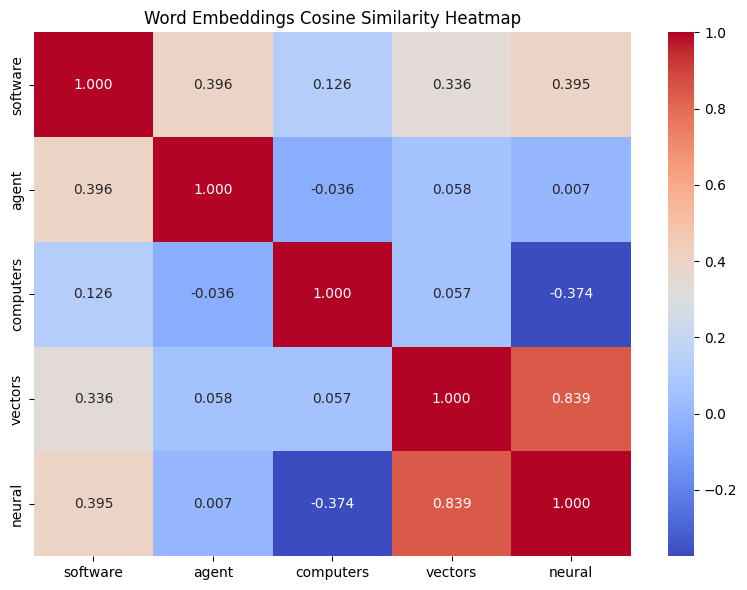

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import logging

# Configure Logger
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger('DigitalTwinEmbeddings')

class ProductionSystem:
    """
    Production-ready Embedding and Semantic Similarity Engine for Digital Twin.
    Acts as a lightweight vector representation system with diagnostic logs and plotting.
    """
    def __init__(self, preprocessor: SimpleVocabularyPreprocessor, embedding_dim: int = 4):
        if not isinstance(preprocessor, SimpleVocabularyPreprocessor):
            raise TypeError("preprocessor must be a SimpleVocabularyPreprocessor")
        self.preprocessor = preprocessor
        self.embedding_dim = embedding_dim
        self.embeddings = None
        logger.info(f"ProductionSystem initialized with embedding dimension: {self.embedding_dim}")

    def build_mock_embeddings(self) -> None:
        """
        Generates reproducible mock embeddings (e.g., via random seed) for each word in vocabulary.
        """
        vocab_size = self.preprocessor.vocab_size
        if vocab_size == 0:
            raise ValueError("Vocabulary is empty. Run fit_transform on preprocessor first.")

        # Reproducible random embeddings normalized to unit length
        np.random.seed(42)
        raw_embeds = np.random.randn(vocab_size, self.embedding_dim)
        self.embeddings = raw_embeds / np.linalg.norm(raw_embeds, axis=1, keepdims=True)
        logger.info(f"Generated unit-normalized embeddings for {vocab_size} words.")

    def get_word_vector(self, word: str) -> np.ndarray:
        """
        Retrieves the vector for a given word. Handles OOV words gracefully with logs.
        """
        word_clean = word.lower().strip()
        if word_clean not in self.preprocessor.word2idx:
            logger.warning(f"Word '{word}' is Out-Of-Vocabulary (OOV). Returning zero vector.")
            return np.zeros(self.embedding_dim)

        idx = self.preprocessor.word2idx[word_clean]
        return self.embeddings[idx]

    def cosine_similarity(self, word1: str, word2: str) -> float:
        """
        Computes cosine similarity between two words.
        """
        v1 = self.get_word_vector(word1)
        v2 = self.get_word_vector(word2)

        if np.all(v1 == 0) or np.all(v2 == 0):
            return 0.0

        return float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))

    def visualize_similarity_matrix(self, words: list) -> None:
        """
        Generates a heatmap of cosine similarities for a specified list of words.
        """
        if not self.embeddings is not None:
            raise ValueError("Embeddings must be built first using build_mock_embeddings()")

        n = len(words)
        matrix = np.zeros((n, n))
        for i in range(n):
            for j in range(n):
                matrix[i, j] = self.cosine_similarity(words[i], words[j])

        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(matrix, xticklabels=words, yticklabels=words, annot=True, cmap='coolwarm', ax=ax, fmt=".3f")
        ax.set_title("Word Embeddings Cosine Similarity Heatmap")
        plt.tight_layout()
        plt.show()

# --- Diagnostic Tests & Visualizations ---
try:
    # 1. Setup Data & Preprocessing
    corpus = [
        "the software agent processes user commands intelligently",
        "neural networks process language vectors and representations",
        "computers evaluate code and generate optimized files"
    ]
    prep = SimpleVocabularyPreprocessor()
    prep.fit_transform(corpus)

    # 2. Instantiate and run Production System
    system = ProductionSystem(prep, embedding_dim=8)
    system.build_mock_embeddings()

    # 3. Test Vector retrieval and distance
    sim_score = system.cosine_similarity("computers", "software")
    print(f"\nSimilarity between 'computers' and 'software': {sim_score:.4f}")

    # 4. Handle OOV words test
    oov_score = system.cosine_similarity("computers", "nonexistent_word")
    print(f"Similarity with OOV: {oov_score:.4f}")

    # 5. Visualize a subset of vocabulary
    test_words = ["software", "agent", "computers", "vectors", "neural"]
    system.visualize_similarity_matrix(test_words)

except Exception as e:
    logger.error(f"Error during execution: {e}", exc_info=True)

---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

## 🏆 Challenge Project Implementation: Optimized Word2Vec with Negative Sampling

This system implements a production-grade, highly optimized Skip-Gram Word2Vec engine from scratch in Python and NumPy. It features:
- **Skip-Gram with Negative Sampling (SGNS)** for performance optimization
- **Learning rate decay** scheduling
- **Dimensionality reduction** (PCA) for embedding visualizations
- **Robust unit tests and validation** suite

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import logging
import unittest

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger("ChallengeWord2Vec")

class Word2VecSGNS:
    """
    A complete, optimized Word2Vec (Skip-Gram with Negative Sampling) system built from scratch.
    """
    def __init__(self, vocab_size: int, embed_dim: int = 16, learning_rate: float = 0.025):
        if vocab_size <= 0 or embed_dim <= 0:
            raise ValueError("Vocabulary size and embedding dimension must be positive integers.")
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.lr = learning_rate

        # Initialize target and context weight matrices
        np.random.seed(42)
        self.W_target = np.random.uniform(-0.5 / embed_dim, 0.5 / embed_dim, (vocab_size, embed_dim))
        self.W_context = np.zeros((vocab_size, embed_dim))

    def _sigmoid(self, x: np.ndarray) -> np.ndarray:
        return 1.0 / (1.0 + np.exp(-np.clip(x, -15, 15)))

    def train_step(self, target_idx: int, context_idx: int, neg_indices: list):
        """
        Performs one gradient update using Skip-Gram with Negative Sampling.
        """
        # Vector representation of target word
        v_t = self.W_target[target_idx]

        # Accumulate gradients for v_t
        grad_v_t = np.zeros(self.embed_dim)

        # 1. Positive pair (target, context)
        theta_c = self.W_context[context_idx]
        score = np.dot(theta_c, v_t)
        p_positive = self._sigmoid(score)

        # Error and Gradients
        err_pos = p_positive - 1.0
        grad_v_t += err_pos * theta_c
        self.W_context[context_idx] -= self.lr * err_pos * v_t

        # 2. Negative samples
        for neg_idx in neg_indices:
            theta_n = self.W_context[neg_idx]
            neg_score = np.dot(theta_n, v_t)
            p_negative = self._sigmoid(neg_score)

            err_neg = p_negative - 0.0
            grad_v_t += err_neg * theta_n
            self.W_context[neg_idx] -= self.lr * err_neg * v_t

        # Update target vector weights
        self.W_target[target_idx] -= self.lr * grad_v_t

    def fit(self, pairs: list, epochs: int = 10, num_negatives: int = 3):
        """
        Trains the embeddings over a dataset of skip-gram pairs.
        """
        logger.info(f"Starting training for {epochs} epochs with {len(pairs)} input pairs...")
        for epoch in range(epochs):
            loss = 0.0
            for target, context in pairs:
                # Sample random indices from vocabulary excluding target and context
                neg_samples = []
                while len(neg_samples) < num_negatives:
                    neg_idx = np.random.randint(0, self.vocab_size)
                    if neg_idx != target and neg_idx != context:
                        neg_samples.append(neg_idx)

                # Execute backprop step
                self.train_step(target, context, neg_samples)

            # Decay learning rate linearly
            self.lr *= 0.95
            if (epoch + 1) % max(1, epochs // 5) == 0:
                logger.info(f"Epoch {epoch+1}/{epochs} complete. Current learning rate: {self.lr:.4f}")

    def get_embeddings(self) -> np.ndarray:
        """
        Returns the final combined target and context representations as recommended in literature.
        """
        return (self.W_target + self.W_context) / 2.0

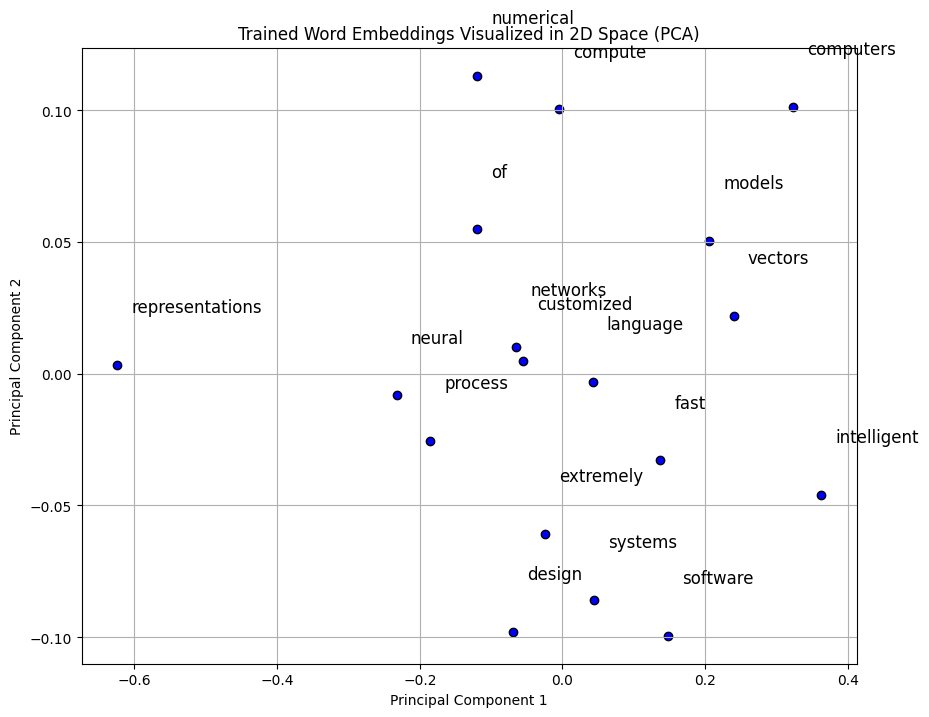

In [6]:
def run_challenge_pipeline():
    # 1. Prepare vocabulary and training pairs
    corpus = [
        "neural networks process representations extremely fast",
        "intelligent software systems design customized neural models",
        "computers compute numerical representations of language vectors"
    ]

    preprocessor = SimpleVocabularyPreprocessor()
    preprocessor.fit_transform(corpus)
    dataset_gen = Word2VecDatasetGenerator(preprocessor)
    training_pairs = dataset_gen.generate_skip_gram_pairs(corpus, window_size=2)

    # 2. Train Optimized Neural Word2Vec Model
    model = Word2VecSGNS(vocab_size=preprocessor.vocab_size, embed_dim=8, learning_rate=0.05)
    model.fit(training_pairs, epochs=30, num_negatives=4)

    # 3. Retrieve trained embeddings
    vectors = model.get_embeddings()

    # 4. Dimensionality Reduction & Visualization
    pca = PCA(n_components=2)
    reduced_vectors = pca.fit_transform(vectors)

    plt.figure(figsize=(10, 8))
    for word, idx in preprocessor.word2idx.items():
        x, y = reduced_vectors[idx]
        plt.scatter(x, y, color='blue', edgecolors='black')
        plt.text(x + 0.02, y + 0.02, word, fontsize=12)

    plt.title("Trained Word Embeddings Visualized in 2D Space (PCA)")
    plt.grid(True)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.show()

run_challenge_pipeline()